In [2]:
#IMPORT LIBS
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
from datetime import timedelta
import cartopy.util as cutil
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
import pandas as pd

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [3]:
from matplotlib import font_manager as fm
for f in fm.findSystemFonts():
    if "times" in f.lower():
        prop = fm.FontProperties(fname=f)
        print(f, " -> ", prop.get_name())

### Mask definition

In [4]:
def find_box_corners(plon,plat,lon_edge,lat_edge):
    lat_min, lat_max = (plat-lat_edge/2)-20,plat+(lat_edge/2)
    lon_min, lon_max = (plon-lon_edge/2),plon+(lon_edge/2)
    if lon_max % 2.5 == 0:
        lon_max -= 0.0001
    if lat_max % 2.5 == 0:
        lat_max -= 0.0001
    return lat_min,lat_max,lon_min,lon_max

In [5]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

### Import data

In [6]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking


In [7]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries/
dic_for_filtering_DAV = np.load('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dic_for_filtering_GHA = np.load('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dics =(dic_for_filtering_DAV,dic_for_filtering_GHA)

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/dictionaries


In [8]:
GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
np_array_GHA = GHA_filt.values
np_array_DAV = DAV_filt.values
np_arrays = (np_array_DAV,np_array_GHA)
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']
#ilon = list(ds_filt_DAV.lon.values).index(ds_filt_DAV.sel(lon=plon, method='nearest').lon)
#ilat = list(ds_filt_DAV.lat.values).index(ds_filt_DAV.sel(lat=plat, method='nearest').lat)
months = ['06','07','08']

# FIGURE 1 
## Trajectories

In [9]:
#create a list of labels for each IBI
#element 0 is DAV, 1 is GHA, 2 is MIX
dics_to_save = [[],[]]
labels = [[],[]]
timings = [[],[]]
min_pers = (3,3)
for t,time in tqdm(enumerate(times)):
    month = str(time.values)[5:7]
    if t > len(times.values)-5:
        break
    if month in months:
        for i,arr in enumerate(np_arrays):
            labels_of_the_day = np.unique(arr[t,mask_bool])
            for label in labels_of_the_day:
                check_cond = []
                for k in range(min_pers[i]):
                    #check_cond.append(np.sum(arr[t+k,mask_bool]==label)/np.sum(mask_bool) > 0.1)
                    check_cond.append(np.any(arr[t+k,mask_bool]==label))
                if label not in labels[i] and np.all(check_cond) and label!=0:
                    dics_to_save[i].append(dics[i][label])
                    dics_to_save[i][-1]['time_arrival_GR'] = t
                    dics_to_save[i][-1]['day_arrival_GR'] = time
                    dics_to_save[i][-1]['original_label'] = label
                    labels[i].append(label)
                    timings[i].append(t)
                    dics[i][label]['day_of_arrival'] = time

30677it [00:09, 3104.67it/s]


In [10]:
np.save('/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/ERA5/ERA5_dic_GR_block_DAV_jja.npy',dics_to_save[0])
np.save('/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/ERA5/ERA5_dic_GR_block_GHA_jja.npy',dics_to_save[1])

In [11]:
areas = [[],[]]
persistences = [[],[]]
intensities = [[],[]]
WBIS = [[],[]]
for j in range(2):
    for label in labels[j]:
        areas[j].append(np.mean(dics[j][label]['area']))
        persistences[j].append(dics[j][label]['persistence'])
        intensities[j].append(np.mean(np.array(dics[j][label]['intensity'])))
        WBIS[j].append(np.mean(np.array(dics[j][label]['WBI'])))

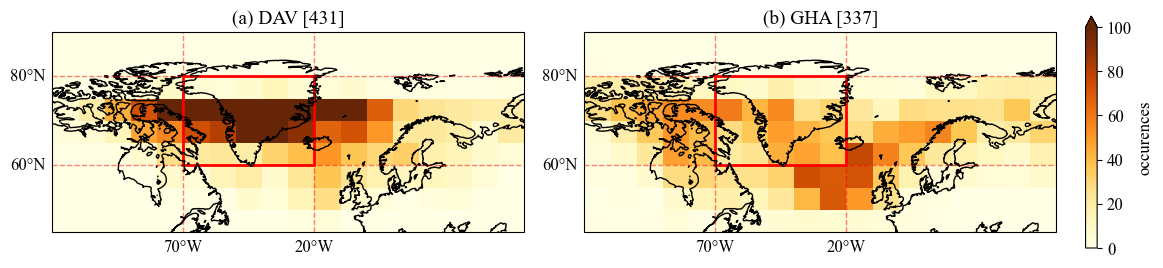

In [12]:
'''
TRAJECTORY PLOT
'''
from matplotlib.patches import Rectangle
import matplotlib.ticker as mticker


fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree()},gridspec_kw={'width_ratios': [1, 1.25]})
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
titles = ['(a) DAV [' + str(len(labels[0])) + ']','(b) GHA [' + str(len(labels[1])) + ']']
datacrs = ccrs.PlateCarree()
extent =[-120,+60,45,90]
#extent =[-180,+180,45,90]

for j in range(2):
    axarr[j].coastlines()
    gl = axarr[j].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
         linewidth=1, color='red', alpha=0.5, linestyle='--') 
    gl.top_labels = False
    gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([-70, -20])
    gl.ylocator = mticker.FixedLocator([60, 80])
    axarr[j].set_aspect(1.7)
    axarr[j].set_title(titles[j])
    xs = []
    ys = []
    for label in labels[j][1:]:
        for x in dics[j][label]['track'][1]:
            xs.append(x)
        for y in dics[j][label]['track'][0]:
            ys.append(y)
    hist = axarr[j].hist2d(xs, ys, bins=(18, 9), range=[[-120, 60], [45, 90]], cmap='YlOrBr',vmin=0,vmax=100,transform=datacrs)  # Adjust bins as needed
   
    box = Rectangle(
        (lon_min, lat_min),  # Bottom-left corner
        lon_max - lon_min,   # Width (longitude difference)
        lat_max - lat_min,   # Height (latitude difference)
        linewidth= 2,
        edgecolor='red',
        facecolor='none',  # Transparent fill
        transform=datacrs  # Ensure proper projection
    )
    
    # Add the box to the plot
    axarr[j].add_patch(box)
    axarr[j].set_extent(extent,crs=datacrs)

cb2 = plt.colorbar(hist[3], ax=axarr[1], orientation='vertical', pad=0.05, shrink = 0.5,extend='max',label='occurences')

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure1.png', dpi=300)
    

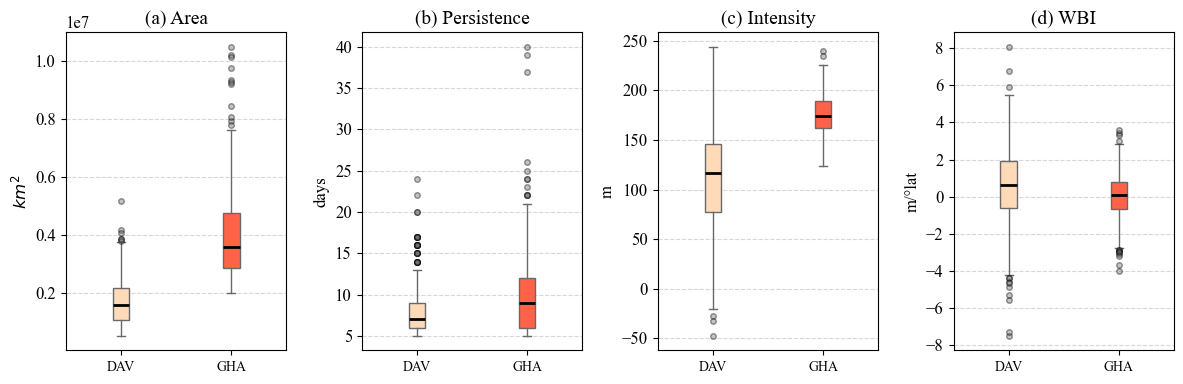

In [25]:
'''
BOXPLOT
'''

#PLOT
#it will be a multiplot devided per attribute: area, persistence and intensity
fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(12, 4))
axs = axs.flatten()

colors = ['peachpuff', 'tomato']
tick_labels = ['DAV','GHA']

axs[0].set_title('(a) Area')
bplot = axs[0].boxplot(areas, vert=True, patch_artist=True,
    boxprops=dict(facecolor="dimgray", color="dimgray"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="dimgray"),
    capprops=dict(color="dimgray"),
    flierprops=dict(marker='o', markersize=4, markerfacecolor="dimgray", alpha=0.4)
)
axs[0].set_xticklabels(tick_labels,fontsize=10)
axs[0].set_ylabel('$km^2$')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('(b) Persistence')
bplot = axs[1].boxplot(persistences, vert=True, patch_artist=True,
    boxprops=dict(facecolor="dimgray", color="dimgray"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="dimgray"),
    capprops=dict(color="dimgray"),
    flierprops=dict(marker='o', markersize=4, markerfacecolor="dimgray", alpha=0.4)
)
axs[1].set_xticklabels(tick_labels,fontsize=10)
axs[1].set_ylabel('days')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[2].set_title('(c) Intensity')
bplot = axs[2].boxplot(intensities, vert=True, patch_artist=True,
    boxprops=dict(facecolor="dimgray", color="dimgray"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="dimgray"),
    capprops=dict(color="dimgray"),
    flierprops=dict(marker='o', markersize=4, markerfacecolor="dimgray", alpha=0.4)
)
axs[2].set_xticklabels(tick_labels,fontsize=10)
axs[2].set_ylabel('m')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[3].set_title('(d) WBI')
bplot = axs[3].boxplot(WBIS, vert=True, patch_artist=True,
    boxprops=dict(facecolor="dimgray", color="dimgray"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="dimgray"),
    capprops=dict(color="dimgray"),
    flierprops=dict(marker='o', markersize=4, markerfacecolor="dimgray", alpha=0.4)
)
axs[3].set_xticklabels(tick_labels,fontsize=10)
axs[3].set_ylabel('m/°lat')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

for ax in axs:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(True)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()   
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure2.png',dpi=300)

# FIGURE 2

## Composites

In [26]:
def deseasonalize(data_arr):
    seasonal_mean = data_arr.groupby('time.dayofyear').mean(dim='time')
    tot_mean = data_arr.mean(dim='time')
    deseasonalized_data_arr = data_arr.groupby('time.dayofyear') - seasonal_mean + tot_mean
    return deseasonalized_data_arr

In [27]:
def detrend(da, dim='time', deg=1):
    # detrend along a single dimension
    p = da.polyfit(dim=dim, deg=deg)
    fit = xr.polyval(da[dim], p.polyfit_coefficients)
    mean = da.mean(dim)
    #print(da-fit+mean)
    return da - fit + mean

In [28]:
#!ATTENTION! this deseasonalization-detrending technique only works when dataset is all-year
def rm_deseasonalize_detrend(data_arr):
    rolling_mean = data_arr.rolling(time=30, center=True, min_periods=1).mean()
    tot_mean = data_arr.mean(dim='time')
    deseasonalized_data_arr = data_arr - rolling_mean + tot_mean
    return deseasonalized_data_arr

In [29]:
#bootstrap function for statistical significance
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in tqdm(range(n_iter)):
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

In [30]:
#open composite datasets
ds_temp = xr.open_dataset('../../temperature/ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc')
ds_IVT = xr.open_dataset('../../IVT/ERA5_IVT_northem_daily_2.5x2.5_jja_1940-2023_mod.nc')

In [31]:
zg = ds_filt_DAV['zg']/9.81
#IVT = rm_deseasonalize_detrend(ds_IVT['IVT'])
#t2m = rm_deseasonalize_detrend(ds_temp['t2m'])
IVT = deseasonalize(ds_IVT['IVT'])
t2m = deseasonalize(ds_temp['t2m'])

### Lagrangian composites

In [32]:
labels_retrograding = [[],[]]
labels_upstream = [[],[]]
day_of_arrival_retrograding = [[],[]]
day_of_arrival_upstream = [[],[]]
zg_retrograding = [[],[]]
zg_upstream = [[],[]]
t2m_retrograding = [[],[]]
t2m_upstream = [[],[]]
IVT_retrograding = [[],[]]
IVT_upstream = [[],[]]
zg_mean = zg.mean('time')
IVT_mean  = IVT.mean('time')
IVT_std = IVT.std('time')
t2m_mean = t2m.mean('time')
t2m_std = t2m.std('time')

#populating the lists
for i,arr in enumerate(np_arrays):
    count = 0
    count_success = 0
    for j,label in tqdm(enumerate(labels[i])):
        if sum(dics[i][label]['WBI']) > 0:
        #if np.mean(np.array(dics[i][label]['intensity'])) <= percentiles_l[i]:
        #if np.mean(np.array(dics[i][label]['WBI'])) <= percentiles_l[i]:
        #if dics[i][label]['track'][1][0] > plon:
            labels_retrograding[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if np.any(arr[t,mask_bool] == label):
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[i][label]['track'][1][dt],dics[i][label]['track'][0][dt],90,30)
                        if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                            count += 1
                        else:
                            count_success += 1
                            zg_retrograding[i].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                            t2m_retrograding[i].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            IVT_retrograding[i].append(((IVT.loc[date,:,:]-IVT_mean)/IVT_std).loc[lat_min:lat_max,lon_min:lon_max].values)
        if sum(dics[i][label]['WBI']) <= 0:   
        #if np.mean(np.array(dics[i][label]['intensity'])) > percentiles_h[i]:
        #if np.mean(np.array(dics[i][label]['WBI'])) > percentiles_h[i]:
        #if dics[i][label]['track'][1][0] <= plon:
            labels_upstream[i].append(label)
            for t in range(dics[i][label]['time'],dics[i][label]['time']+dics[i][label]['persistence']): 
                if np.any(arr[t,mask_bool] == label):
                    dt = t-dics[i][label]['time']
                    date = dics[i][label]['date'] + np.timedelta64(dt,'D')# - np.timedelta64(3,'D')
                    month = str(date)[5:7]
                    if month in months:
                        lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[i][label]['track'][1][dt],dics[i][label]['track'][0][dt],90,30)
                        if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                            count += 1
                        else:
                            count_success += 1
                            zg_upstream[i].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                            t2m_upstream[i].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                            IVT_upstream[i].append(((IVT.loc[date,:,:]-IVT_mean)/IVT_std).loc[lat_min:lat_max,lon_min:lon_max].values)
    print(count, count_success)
#computing the composites
zg_retrograding_comp = [0,0,0]
zg_retrograding_t_st = [0,0,0]
zg_upstream_comp = [0,0,0]
zg_upstream_t_st = [0,0,0]
IVT_retrograding_comp = [0,0,0]
IVT_retrograding_t_st = [0,0,0]
IVT_upstream_comp = [0,0,0]
IVT_upstream_t_st = [0,0,0]
t2m_retrograding_comp = [0,0,0]
t2m_retrograding_t_st = [0,0,0]
t2m_upstream_comp = [0,0,0]
t2m_upstream_t_st = [0,0,0]

print(len(labels_retrograding[0]),len(labels_upstream[0]),len(labels_retrograding[1]),len(labels_upstream[1]))
print(len(zg_retrograding[0]),len(zg_upstream[0]),len(zg_retrograding[1]),len(zg_upstream[1]))

431it [00:07, 53.99it/s]


0 2648


337it [00:05, 58.60it/s]

251 1893
269 162 183 154
1657 991 1031 862


In [33]:
for i,var in enumerate(('DAV','GHA')):

    lat_min,lat_max,lon_min,lon_max = find_box_corners(-35,70,90,30)
    'ZG'
    zg_retrograding_comp[i] = sum(zg_retrograding[i])/len(zg_retrograding[i])
    zg_upstream_comp[i] = sum(zg_upstream[i])/len(zg_upstream[i])

    print(len(labels_retrograding[i]),len(labels_upstream[i]))
    'IVT'
    IVT_retrograding_comp[i] = sum(IVT_retrograding[i])/len(IVT_retrograding[i])# - IVT_mean
    IVT_retrograding_t_st[i] = abs(IVT_retrograding_comp[i]/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVT_retrograding[i]),100)) > 2
    IVT_upstream_comp[i] = sum(IVT_upstream[i])/len(IVT_upstream[i])# - IVT_mean
    IVT_upstream_t_st[i] = abs(IVT_upstream_comp[i]/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVT_upstream[i]),100)) > 2

    't2m'
    t2m_retrograding_comp[i] = sum(t2m_retrograding[i])/len(t2m_retrograding[i])# - t2m_mean
    t2m_retrograding_t_st[i] = abs(t2m_retrograding_comp[i]/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2m_retrograding[i]),100)) > 2
    t2m_upstream_comp[i] = sum(t2m_upstream[i])/len(t2m_upstream[i])# - t2m_mean
    t2m_upstream_t_st[i] = abs(t2m_upstream_comp[i]/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2m_upstream[i]),100)) > 2


269 162


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 447.99it/s]


183 154


100%|████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 501.64it/s]


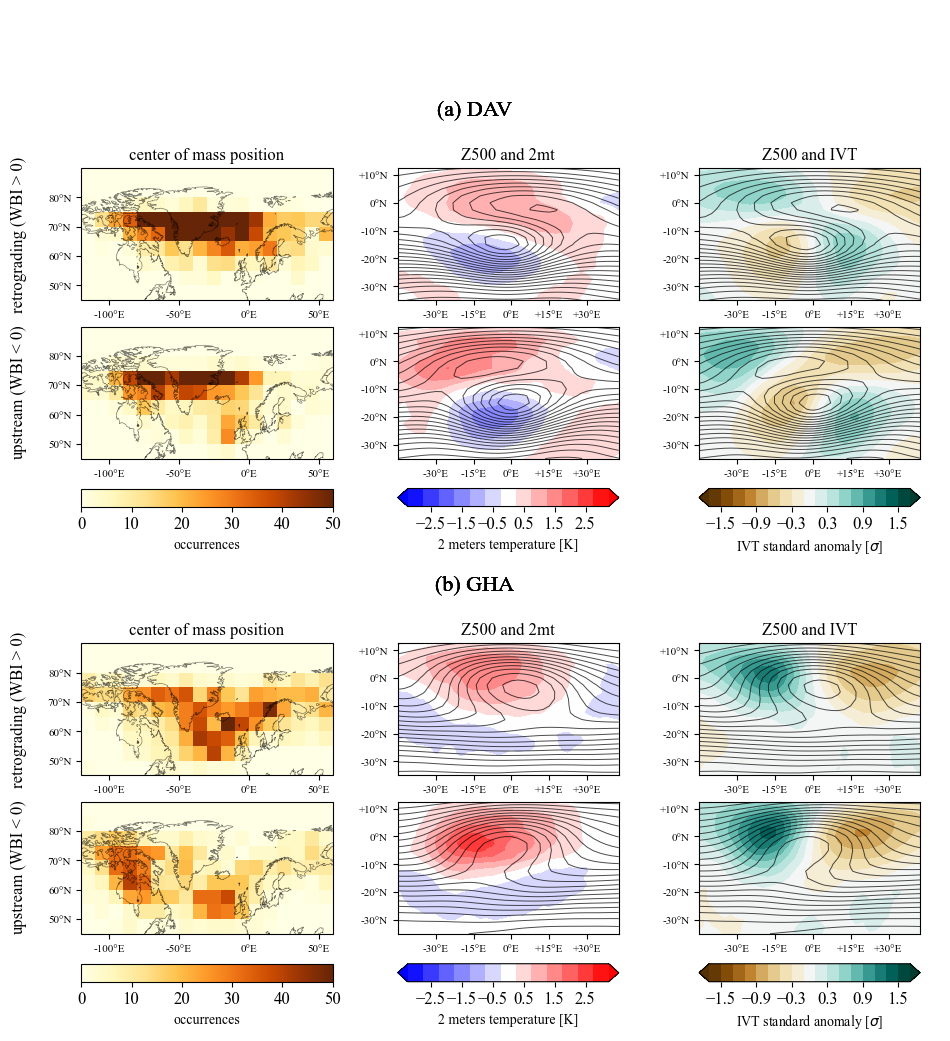

In [34]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import numpy as np

# --------------------------------------------------
# PARAMETERS (UNCHANGED)
# --------------------------------------------------
ncols = 4
nrows = 6

big_titles_fontsize = 16
small_titles_fontsize = 12
colorbar_fontsize = 10

small_titles = ['trajectories', 'Z500 and 2mt', 'Z500 and IVT']

datacrs = ccrs.PlateCarree()

density = 2
alpha_cont = 0.7
linewidths_cont = 0.7

#levels:
z_levels = np.arange(4620,6000,20)
t2m_range = np.arange(-3.25,3.3,0.5)
t2m_ticks = np.arange(-2.5,2.6,1)
IVT_range = np.arange(-1.7,1.75,0.2)
IVT_ticks = [-1.5,-0.9,-0.3,0.3,0.9,1.5]#(-0.0225,-0.01,int(0),0.01,0.0225)

# --------------------------------------------------
# FIGURE & GRID
# --------------------------------------------------
fig = plt.figure(figsize=(12, 12))
gs = gridspec.GridSpec(
    nrows, ncols,
    width_ratios=[0.1, 1, 1, 1],
    height_ratios=[1 , 1, 1, 1, 1, 1],
    hspace=0.2,
    wspace=0.2
)

# --------------------------------------------------
# MAIN LOOP
# --------------------------------------------------
for j in range(nrows):
    for i in range(ncols):

        # =====================================================
        # TITLE ROWS
        # =====================================================
        if j % 3 == 0:
            ax = fig.add_subplot(gs[j, :])
            ax.axis('off')

            if j == 0:
                ax.text(0.5, 0.2, '(a) DAV',
                        ha='center', fontsize=big_titles_fontsize)
            elif j == 3:
                ax.text(0.5, 0.2, '(b) GHA',
                        ha='center', fontsize=big_titles_fontsize)
            continue

        # =====================================================
        # LEFT LABEL COLUMN
        # =====================================================
        if i == 0:
            ax = fig.add_subplot(gs[j, i])
            ax.axis('off')

            if j in [1, 4]:
                ax.text(
                    0.35, 0.5,
                    'retrograding (WBI > 0)',
                    rotation='vertical',
                    ha='center', va='center',
                    fontsize=small_titles_fontsize
                )
            elif j in [2, 5]:
                ax.text(
                    0.35, 0.5,
                    'upstream (WBI < 0)',
                    rotation='vertical',
                    ha='center', va='center',
                    fontsize=small_titles_fontsize
                )
            continue

        # =====================================================
        # HISTOGRAMS (COLUMN 1)
        # =====================================================
        if i == 1:
            ax = fig.add_subplot(gs[j, i], projection=datacrs)
            extent =[-120,+60,45,90]
            ax.set_extent(extent, crs=datacrs)
            ax.coastlines(linewidth=0.5, alpha=0.5)

            # ---- data selection
            xs, ys = [], []

            if (j - 1) % 3 == 0:
                k = int((j - 1) / 3)
                for label in labels_retrograding[k]:
                    xs.extend(dics[k][label]['track'][1])
                    ys.extend(dics[k][label]['track'][0])

            elif (j - 2) % 3 == 0:
                k = int((j - 2) / 3)
                for label in labels_upstream[k]:
                    xs.extend(dics[k][label]['track'][1])
                    ys.extend(dics[k][label]['track'][0])

            hist = ax.hist2d(
                xs, ys,
                bins=(18, 9),
                range=[[extent[0], extent[1]], [extent[2], extent[3]]],
                cmap='YlOrBr',
                vmin=0, vmax=50,
                transform=datacrs
            )

            ax.autoscale(False)
            ax.set_extent(extent, crs=datacrs)

            ax.set_xticks(
                [-100, -50, 0, 50],
                crs=datacrs
            )
            ax.set_xticklabels(
                [ '-100°E', '-50°E', '0°E', '50°E'],
                fontsize=8
            )
            ax.set_yticks(
                [50, 60, 70, 80],
                crs=datacrs
            )
            ax.set_yticklabels(
                ['50°N', '60°N', '70°N', '80°N'],
                fontsize=8
            )

            ax.tick_params(labelsize=8)

            ax.set_aspect(2.1)

            # ---- histogram colorbar (explicit axis)
            if (j - 2) % 3 == 0:
                pos = ax.get_position()
                cax = fig.add_axes([
                    pos.x0,
                    pos.y0 - 0.040,
                    pos.width,
                    0.015
                ])

                cb = fig.colorbar(
                    hist[3],
                    cax=cax,
                    orientation='horizontal'
                )
                cb.set_label(
                    'occurrences',
                    fontsize=colorbar_fontsize
                )

            if j == 1 or j==4:
                ax.set_title('center of mass position',fontsize=small_titles_fontsize)

        # =====================================================
        # COMPOSITES (COLUMNS 2 & 3)
        # =====================================================
        if i in [2, 3]:
            ax = fig.add_subplot(gs[j, i])
            ax.set_aspect(1.1)

            ax.set_xticks([6, 12, 18, 24, 30])
            ax.set_yticks([2, 6, 10, 14, 18])

            ax.set_xticklabels(
                ['-30°E', '-15°E', '0°E', '+15°E', '+30°E'],
                fontsize=8
            )
            ax.set_yticklabels(
                ['-30°N', '-20°N', '-10°N', '0°N', '+10°N'],
                fontsize=8
            )

            if (j - 1) % 3 == 0:
                ax.set_title(
                    small_titles[i - 1],
                    fontsize=small_titles_fontsize
                )

            # -------------------------
            # T2M COMPOSITES
            # -------------------------
            if i == 2 and (j - 1) % 3 == 0:
                k = int((j - 1) / 3)
                plt.contour(
                    zg_retrograding_comp[k],
                    z_levels,
                    linewidths=linewidths_cont,
                    alpha=alpha_cont,
                    colors='black'
                )
                shad = plt.contourf(
                    t2m_retrograding_comp[k],
                    levels=t2m_range,
                    cmap='bwr',
                    extend='both'
                )

            if i == 2 and (j - 2) % 3 == 0:
                k = int((j - 2) / 3)
                plt.contour(
                    zg_upstream_comp[k],
                    z_levels,
                    linewidths=linewidths_cont,
                    alpha=alpha_cont,
                    colors='black'
                )
                shad = plt.contourf(
                    t2m_upstream_comp[k],
                    levels=t2m_range,
                    cmap='bwr',
                    extend='both'
                )
                
                pos = ax.get_position()
                cax = fig.add_axes([
                    pos.x0,
                    pos.y0 - 0.040,
                    pos.width,
                    0.015
                ])

                cb = fig.colorbar(
                    shad,
                    cax=cax,
                    orientation='horizontal',
                    ticks=t2m_ticks
                )
                cb.set_label(
                    '2 meters temperature [K]',
                    fontsize=colorbar_fontsize
                )
                
            # -------------------------
            # IVT COMPOSITES
            # -------------------------
            if i == 3 and (j - 1) % 3 == 0:
                k = int((j - 1) / 3)
                plt.contour(
                    zg_retrograding_comp[k],
                    z_levels,
                    linewidths=linewidths_cont,
                    alpha=alpha_cont,
                    colors='black'
                )
                shad = plt.contourf(
                    IVT_retrograding_comp[k],
                    levels=IVT_range,
                    cmap='BrBG',
                    extend='both'
                )

            if i == 3 and (j - 2) % 3 == 0:
                k = int((j - 2) / 3)
                plt.contour(
                    zg_upstream_comp[k],
                    z_levels,
                    linewidths=linewidths_cont,
                    alpha=alpha_cont,
                    colors='black'
                )
                shad = plt.contourf(
                    IVT_upstream_comp[k],
                    levels=IVT_range,
                    cmap='BrBG',
                    extend='both'
                )

                pos = ax.get_position()
                cax = fig.add_axes([
                    pos.x0,
                    pos.y0 - 0.040,
                    pos.width,
                    0.015
                ])

                cb = fig.colorbar(
                    shad,
                    cax=cax,
                    orientation='horizontal',
                    ticks=IVT_ticks
                )
                cb.set_label(
                    r'IVT standard anomaly [$\sigma$]',
                    fontsize=colorbar_fontsize
                )

# --------------------------------------------------
# SAVE
# --------------------------------------------------
plt.savefig(
    '/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure3.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


In [38]:
print([int(x) for x in labels_retrograding[1]])

[8, 17, 74, 80, 107, 108, 113, 147, 151, 176, 178, 188, 190, 228, 259, 265, 267, 271, 306, 309, 310, 349, 382, 388, 409, 415, 422, 453, 460, 536, 570, 573, 645, 653, 685, 692, 725, 728, 731, 766, 769, 775, 809, 842, 849, 881, 883, 890, 916, 924, 960, 961, 963, 999, 1080, 1085, 1127, 1130, 1131, 1165, 1168, 1172, 1204, 1243, 1245, 1276, 1279, 1283, 1318, 1319, 1328, 1356, 1362, 1393, 1396, 1403, 1428, 1434, 1467, 1469, 1477, 1504, 1513, 1546, 1550, 1552, 1591, 1620, 1623, 1630, 1663, 1664, 1667, 1668, 1692, 1695, 1705, 1738, 1772, 1780, 1783, 1807, 1810, 1813, 1814, 1849, 1881, 1887, 1892, 1921, 1922, 1957, 1959, 1991, 1992, 2030, 2039, 2064, 2067, 2071, 2101, 2102, 2107, 2110, 2116, 2187, 2194, 2228, 2233, 2271, 2275, 2280, 2281, 2314, 2318, 2350, 2353, 2362, 2387, 2435, 2464, 2471, 2472, 2496, 2499, 2504, 2529, 2532, 2570, 2610, 2616, 2622, 2651, 2660, 2700, 2735, 2743, 2766, 2777, 2779, 2813, 2838, 2882, 2915, 2922, 2923, 2989, 2995, 2997, 2996, 3038, 3040, 3065, 3066, 3073, 3074, 30

In [39]:
print([int(x) for x in labels_upstream[1]])

[13, 44, 103, 104, 146, 182, 185, 220, 222, 225, 230, 268, 312, 347, 354, 384, 386, 414, 498, 502, 508, 540, 543, 545, 577, 611, 615, 616, 621, 649, 687, 688, 776, 804, 802, 841, 844, 887, 918, 926, 955, 958, 997, 998, 1032, 1039, 1083, 1087, 1088, 1122, 1124, 1126, 1171, 1206, 1241, 1278, 1287, 1286, 1291, 1320, 1323, 1324, 1392, 1395, 1431, 1509, 1516, 1549, 1583, 1629, 1634, 1665, 1670, 1697, 1698, 1734, 1742, 1744, 1773, 1775, 1845, 1847, 1848, 1853, 1883, 1889, 1920, 1924, 1925, 1954, 1960, 1997, 2032, 2072, 2074, 2149, 2191, 2193, 2197, 2230, 2231, 2273, 2279, 2315, 2320, 2356, 2358, 2388, 2395, 2428, 2429, 2434, 2468, 2498, 2535, 2536, 2539, 2572, 2611, 2617, 2618, 2658, 2692, 2693, 2704, 2706, 2705, 2737, 2740, 2806, 2810, 2815, 2840, 2846, 2848, 2876, 2880, 2884, 2921, 2928, 2960, 2963, 2991, 3034, 3036, 3078, 3109, 3110, 3148, 3156, 3186, 3188, 3190, 3192]


### Boxplot Upstream Retrograding

In [35]:
areas = [[],[],[],[]]
persistences = [[],[],[],[]]
intensities = [[],[],[],[]]
WBIS = [[],[],[],[]]
for j in range(4):
    if j < 2:
        for label in labels_retrograding[j]:
            areas[j].append(np.mean(dics[j][label]['area']))
            persistences[j].append(dics[j][label]['persistence'])
            intensities[j].append(np.mean(np.array(dics[j][label]['intensity'])))
            WBIS[j].append(np.mean(np.array(dics[j][label]['WBI'])))
    if j >= 2:
        for label in labels_upstream[j-2]:
            areas[j].append(np.mean(dics[j-2][label]['area']))
            persistences[j].append(dics[j-2][label]['persistence'])
            intensities[j].append(np.mean(np.array(dics[j-2][label]['intensity'])))
            WBIS[j].append(np.mean(np.array(dics[j-2][label]['WBI'])))


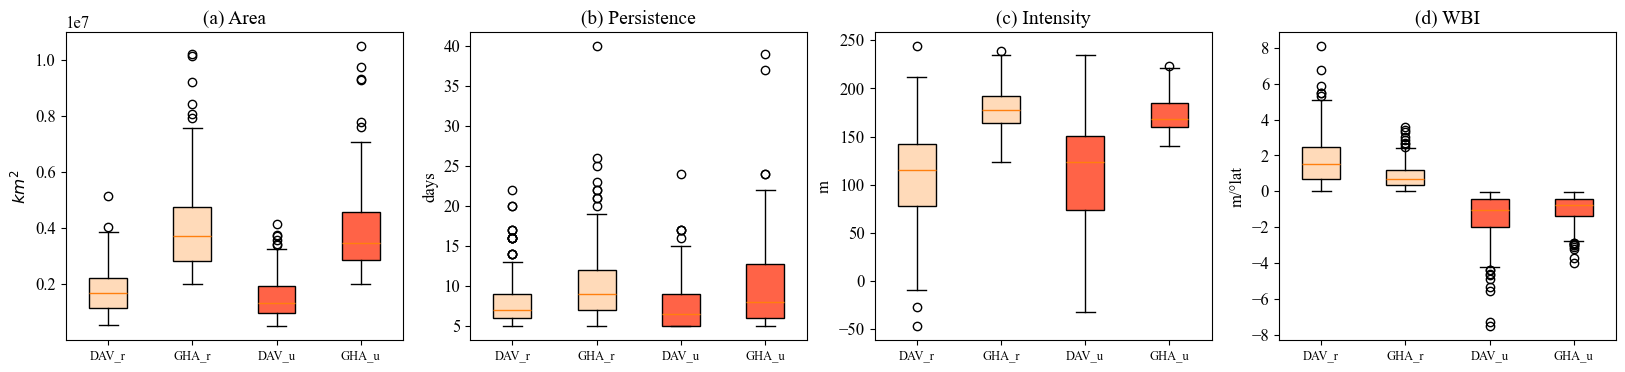

In [23]:
'''
BOXPLOT
'''

#PLOT
#it will be a multiplot devided per attribute: area, persistence and intensity
fig, axs = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))
axs = axs.flatten()

colors = ['peachpuff','peachpuff', 'tomato','tomato']
tick_labels = ['DAV_r','GHA_r','DAV_u','GHA_u']

axs[0].set_title('(a) Area')
bplot = axs[0].boxplot(areas, vert=True, patch_artist=True)
axs[0].set_xticklabels(tick_labels,fontsize=9)
axs[0].set_ylabel('$km^2$')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('(b) Persistence')
bplot = axs[1].boxplot(persistences, vert=True, patch_artist=True)
axs[1].set_xticklabels(tick_labels,fontsize=9)
axs[1].set_ylabel('days')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[2].set_title('(c) Intensity')
bplot = axs[2].boxplot(intensities, vert=True, patch_artist=True)
axs[2].set_xticklabels(tick_labels,fontsize=9)
axs[2].set_ylabel('m')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

axs[3].set_title('(d) WBI')
bplot = axs[3].boxplot(WBIS, vert=True, patch_artist=True)
axs[3].set_xticklabels(tick_labels,fontsize=9)
axs[3].set_ylabel('m/°lat')
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)

### Temporal evolution DAV - Eulerian

In [24]:
dts = [-3,0,3]
arr = np_array_DAV

zgs_retrograding = []
IVTs_retrograding = []
t2ms_retrograding = []

count = 0

for i in dts:
    zgs_retrograding.append([])
    IVTs_retrograding.append([])
    t2ms_retrograding.append([])

for i,label in tqdm(enumerate(labels_retrograding[0])):
    for j in range(len(dts)):        
        for t in range(dics[0][label]['time'],dics[0][label]['time']+dics[0][label]['persistence']): 
            if np.any(arr[t,mask_bool] == label):
                dt = t-dics[0][label]['time']
                date = dics[0][label]['date'] + np.timedelta64(dt,'D') + np.timedelta64(dts[j],'D')
                month = str(date)[5:7]
                if month in months and (dts[j]+dt) < dics[0][label]['persistence']:
                    lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[0][label]['track'][1][dt],dics[0][label]['track'][0][dt],90,30)
                    if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                        count += 1
                    else:
                        count_success += 1
                        zgs_retrograding[j].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                        t2ms_retrograding[j].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                        IVTs_retrograding[j].append((IVT.loc[date,:,:]-IVT_mean).loc[lat_min:lat_max,lon_min:lon_max].values)

print(len(zgs_retrograding[0]),count)
count = 0
zgs_upstream = []
IVTs_upstream = []
t2ms_upstream = []

count = 0

for i in dts:
    zgs_upstream.append([])
    IVTs_upstream.append([])
    t2ms_upstream.append([])

for i,label in tqdm(enumerate(labels_upstream[0])):
    for j in range(len(dts)):        
        for t in range(dics[0][label]['time'],dics[0][label]['time']+dics[0][label]['persistence']): 
            if np.any(arr[t,mask_bool] == label):
                dt = t-dics[0][label]['time']
                date = dics[0][label]['date'] + np.timedelta64(dt,'D') + np.timedelta64(dts[j],'D')
                month = str(date)[5:7]
                if month in months and (dts[j]+dt) < dics[0][label]['persistence']:
                    lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[0][label]['track'][1][dt],dics[0][label]['track'][0][dt],90,30)
                    if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                        count += 1
                    else:
                        count_success += 1
                        zgs_upstream[j].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                        t2ms_upstream[j].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                        IVTs_upstream[j].append(((IVT.loc[date,:,:]-IVT_mean)/IVT_std).loc[lat_min:lat_max,lon_min:lon_max].values)

print(len(zgs_upstream[0]),count)


269it [00:11, 23.92it/s]


1585 0


162it [00:07, 20.51it/s]

969 0


1
2
3


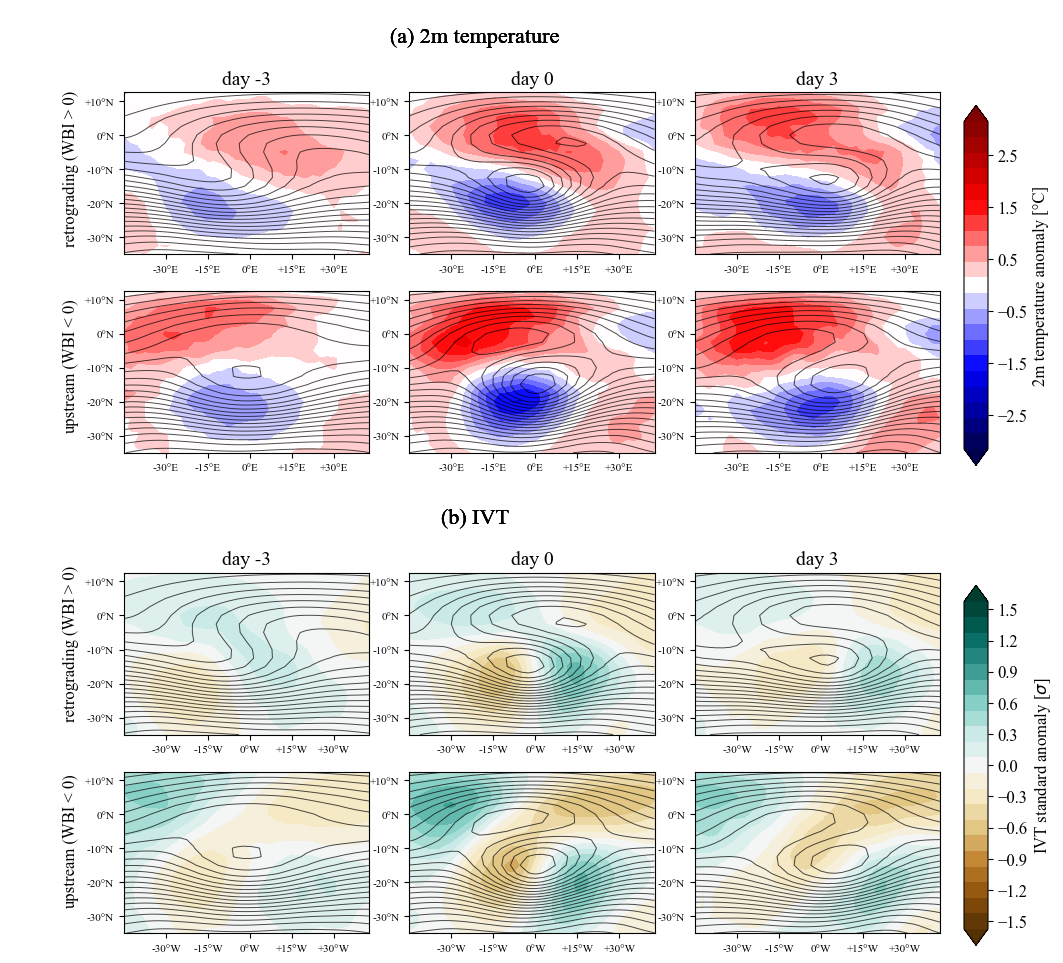

In [25]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 12
colorbar_fontsize = 12

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.3,1,1,1],height_ratios=[0.4,1.4, 1.4, 0.4, 1.4, 1.4], hspace=0.3)
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 40, 90]  # Greenland
density = 2
alpha_cont = 0.7
z_levels = np.arange(4620,6000,20)
t2m_range = np.arange(-3.15,3.2,0.3)
t2m_ticks = np.arange(-2.5,2.6,1)
IVT_range = np.arange(-1.05,1.1,0.1)*1.5
IVT_ticks = np.arange(-1.0,1.1,0.2)*1.5#(-0.0225,-0.01,int(0),0.01,0.0225)

lat_min,lat_max,lon_min,lon_max = find_box_corners(-35,70,90,30)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and j < 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i])
            ax.set_aspect('auto')
            ax.get_yaxis().set_ticks([2,6,10,14,18])
            ax.set_yticklabels(['-30°N','-20°N','-10°N','0°N','+10°N'],fontsize=8)
            ax.get_xaxis().set_ticks([6,12,18,24,30])
            ax.set_xticklabels(['-30°E','-15°E','0°E','+15°E','+30°E'],fontsize=8)
            '-3'
            'retrograding (WBI > 0)'
            if (j-1)%3==0:
                k = int((j-1)/3)
                print(i)
                t2m_comp = sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1])
                #t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2ms_retrograding[i-1]),100)) > 2
                plt.contour( sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7  )
                shad_t2m = plt.contourf( sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1]),t2m_range,cmap='seismic',extend='both'  )
                #hatchings = plt.contourf(t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))
            'upstream (WBI < 0)'
            if (j-2)%3==0:
                k = int((j-1)/3)
                t2m_comp = sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1])
                #t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2ms_upstream[i-1]),100)) > 2
                plt.contour( sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7  )
                shad_t2m = plt.contourf( sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1]),t2m_range,cmap='seismic',extend='both'  )
                #hatchings = plt.contourf( t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                

        if j%3 != 0 and j > 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i])
            ax.set_aspect('auto')
            ax.get_yaxis().set_ticks([2,6,10,14,18])
            ax.set_yticklabels(['-30°N','-20°N','-10°N','0°N','+10°N'],fontsize=8)
            ax.get_xaxis().set_ticks([6,12,18,24,30])
            ax.set_xticklabels(['-30°W','-15°W','0°W','+15°W','+30°W'],fontsize=8)
            '-3'
            'retrograding (WBI > 0)'
            if (j-1)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                #IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVTs_upstream[i-1]),100)) > 2
                plt.contour( sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black'  )
                shad_IVT = plt.contourf( sum(IVTs_retrograding[i-1])/len(IVTs_retrograding[i-1]),IVT_range,cmap='BrBG',extend='both'  )
                #hatchings = plt.contourf( IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))

            'upstream (WBI < 0)'
            if (j-2)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                #IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVTs_upstream[i-1]),100)) > 2
                plt.contour( sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black'  )
                shad_IVT = plt.contourf( sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1]),IVT_range,cmap='BrBG',extend='both'  )
                #hatchings = plt.contourf( IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                

        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(a) 2m temperature' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(b) IVT' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding (WBI > 0)',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream (WBI < 0)',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

# Assuming 'fig' and 'gs' are already defined
cbar_ax_t2m = fig.add_axes([0.92, 0.50, 0.02, 0.3])  # Position for t2m colorbar
cbar_ax_IVT = fig.add_axes([0.92, 0.10, 0.02, 0.3])  # Position for IVT colorbar

# Creating the colorbars
cbar_t2m = fig.colorbar(shad_t2m,aspect=50,shrink = 0.6,cax=cbar_ax_t2m,ticks=t2m_ticks)
cbar_t2m.set_label('2m temperature anomaly [°C]', fontsize=colorbar_fontsize)
cbar_t2m.ax.tick_params(labelsize=colorbar_fontsize)

cbar_IVT = fig.colorbar(shad_IVT,aspect=50,shrink = 0.6,cax=cbar_ax_IVT,ticks=IVT_ticks)
cbar_IVT.set_label(r'IVT standard anomaly [$\sigma$]', fontsize=colorbar_fontsize)
cbar_IVT.ax.tick_params(labelsize=colorbar_fontsize)

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/FigureS1.png', dpi=300)

### Temporal evolution GHA - Eulerian

In [26]:
dts = [-3,0,3]
arr = np_array_GHA

zgs_retrograding = []
IVTs_retrograding = []
t2ms_retrograding = []

count = 0

for i in dts:
    zgs_retrograding.append([])
    IVTs_retrograding.append([])
    t2ms_retrograding.append([])

for i,label in tqdm(enumerate(labels_retrograding[1])):
    for j in range(len(dts)):        
        for t in range(dics[1][label]['time'],dics[1][label]['time']+dics[1][label]['persistence']): 
            if np.any(arr[t,mask_bool] == label):
                dt = t-dics[1][label]['time']
                date = dics[1][label]['date'] + np.timedelta64(dt,'D') + np.timedelta64(dts[j],'D')
                month = str(date)[5:7]
                if month in months and (dts[j]+dt) < dics[1][label]['persistence']:
                    lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[1][label]['track'][1][dt],dics[1][label]['track'][0][dt],90,30)
                    if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                        count += 1
                    else:
                        count_success += 1
                        zgs_retrograding[j].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                        t2ms_retrograding[j].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                        IVTs_retrograding[j].append((IVT.loc[date,:,:]-IVT_mean).loc[lat_min:lat_max,lon_min:lon_max].values)

print(len(zgs_retrograding[0]),count)

count = 0
zgs_upstream = []
IVTs_upstream = []
t2ms_upstream = []

count = 0

for i in dts:
    zgs_upstream.append([])
    IVTs_upstream.append([])
    t2ms_upstream.append([])

for i,label in tqdm(enumerate(labels_upstream[1])):
    for j in range(len(dts)):        
        for t in range(dics[1][label]['time'],dics[1][label]['time']+dics[1][label]['persistence']): 
            if np.any(arr[t,mask_bool] == label):
                dt = t-dics[1][label]['time']
                date = dics[1][label]['date'] + np.timedelta64(dt,'D') + np.timedelta64(dts[j],'D')
                month = str(date)[5:7]
                if month in months and (dts[j]+dt) < dics[1][label]['persistence']:
                    lat_min,lat_max,lon_min,lon_max = find_box_corners(dics[1][label]['track'][1][dt],dics[1][label]['track'][0][dt],90,30)
                    if lat_max > 90 or lon_min < -180 or lon_max > +180 or lat_min < 0:
                        count += 1
                    else:
                        count_success += 1
                        zgs_upstream[j].append(zg.loc[date,lat_min:lat_max,lon_min:lon_max].values)
                        t2ms_upstream[j].append((t2m.loc[date,:,:]-t2m_mean).loc[lat_min:lat_max,lon_min:lon_max].values)
                        IVTs_upstream[j].append(((IVT.loc[date,:,:]-IVT_mean)/IVT_std).loc[lat_min:lat_max,lon_min:lon_max].values)

print(len(zgs_upstream[0]),count)


183it [00:06, 26.35it/s]


1003 323


154it [00:06, 22.74it/s]

862 338


In [27]:
print(t2ms_retrograding[0][0].shape)

(20, 36)


1
2
3


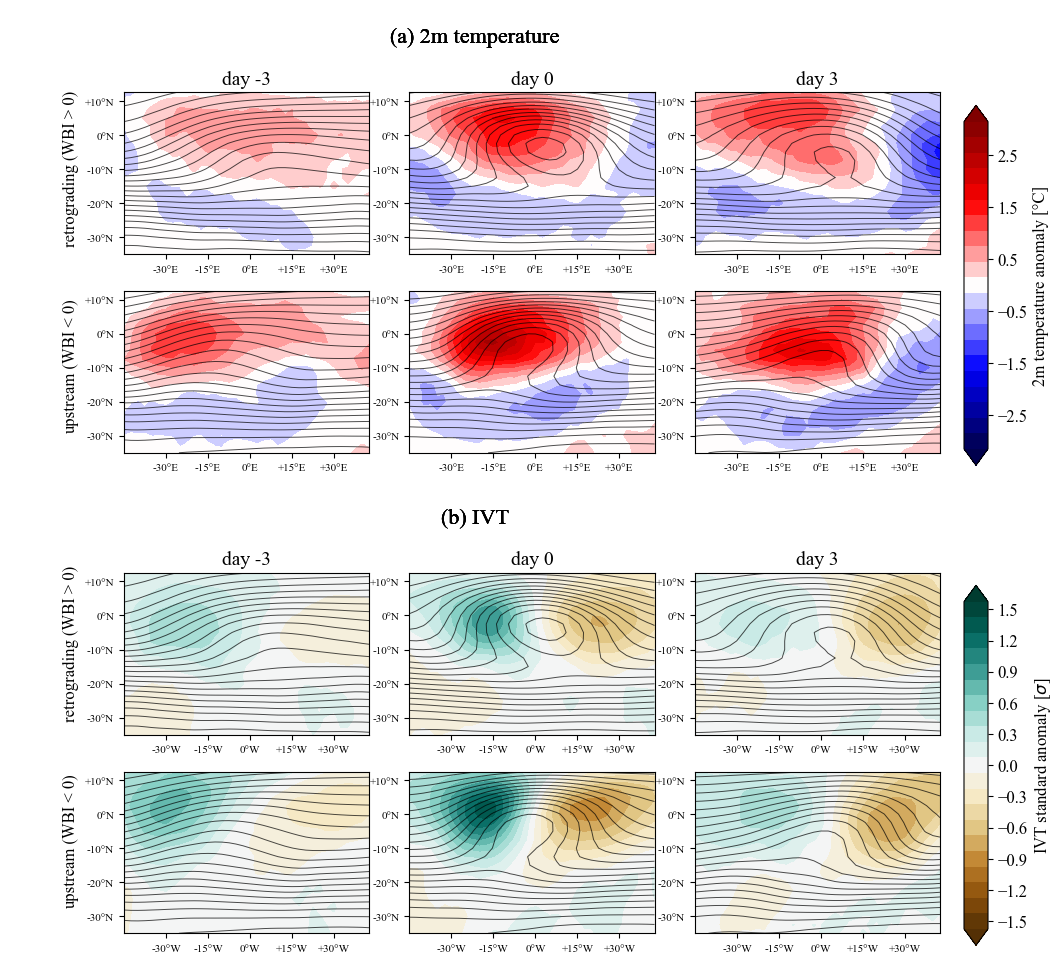

In [28]:
'''
COMPOSITES PLOT
'''
import matplotlib.gridspec as gridspec

ncols=4
nrows=6

big_titles_fontsize = 16
small_titles_fontsize = 12
colorbar_fontsize = 12

fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12,12))
gs = gridspec.GridSpec(nrows, ncols, width_ratios=[0.3,1,1,1],height_ratios=[0.4,1.4, 1.4, 0.4, 1.4, 1.4], hspace=0.3)
lon = ds_filt_DAV['lon']
lat = ds_filt_DAV['lat']
datacrs = ccrs.PlateCarree()
extent = [-100, 40, 40, 90]  # Greenland
density = 2
alpha_cont = 0.7
z_levels = np.arange(4620,6000,20)
t2m_range = np.arange(-3.15,3.2,0.3)
t2m_ticks = np.arange(-2.5,2.6,1)
IVT_range = np.arange(-1.05,1.1,0.1)*1.5
IVT_ticks = np.arange(-1.0,1.1,0.2)*1.5#(-0.0225,-0.01,int(0),0.01,0.0225)

lat_min,lat_max,lon_min,lon_max = find_box_corners(-35,70,90,30)

'PLOTS'
for i in range(ncols):
    for j in range(nrows):
        if j%3 != 0 and j < 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i])
            ax.set_aspect('auto')
            ax.get_yaxis().set_ticks([2,6,10,14,18])
            ax.set_yticklabels(['-30°N','-20°N','-10°N','0°N','+10°N'],fontsize=8)
            ax.get_xaxis().set_ticks([6,12,18,24,30])
            ax.set_xticklabels(['-30°E','-15°E','0°E','+15°E','+30°E'],fontsize=8)
            '-3'
            'retrograding (WBI > 0)'
            if (j-1)%3==0:
                k = int((j-1)/3)
                print(i)
                t2m_comp = sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1])
                #t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2ms_retrograding[i-1]),100)) > 2
                plt.contour( sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7  )
                shad_t2m = plt.contourf( sum(t2ms_retrograding[i-1])/len(t2ms_retrograding[i-1]),t2m_range,cmap='seismic',extend='both'  )
                #hatchings = plt.contourf(t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))
            'upstream (WBI < 0)'
            if (j-2)%3==0:
                k = int((j-1)/3)
                t2m_comp = sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1])
                #t2m_comp_t_st = abs(t2m_comp/Bootstrap(t2m.loc[:,lat_min:lat_max,lon_min:lon_max],len(t2ms_upstream[i-1]),100)) > 2
                plt.contour( sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels, colors = 'black',linewidths=0.7,alpha=0.7  )
                shad_t2m = plt.contourf( sum(t2ms_upstream[i-1])/len(t2ms_upstream[i-1]),t2m_range,cmap='seismic',extend='both'  )
                #hatchings = plt.contourf( t2m_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                

        if j%3 != 0 and j > 3 and i!=0:
            axarr[j,i].axis('off')
            ax = fig.add_subplot(gs[j,i])
            ax.set_aspect('auto')
            ax.get_yaxis().set_ticks([2,6,10,14,18])
            ax.set_yticklabels(['-30°N','-20°N','-10°N','0°N','+10°N'],fontsize=8)
            ax.get_xaxis().set_ticks([6,12,18,24,30])
            ax.set_xticklabels(['-30°W','-15°W','0°W','+15°W','+30°W'],fontsize=8)
            '-3'
            'retrograding (WBI > 0)'
            if (j-1)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                #IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVTs_upstream[i-1]),100)) > 2
                plt.contour( sum(zgs_retrograding[i-1])/len(zgs_retrograding[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black'  )
                shad_IVT = plt.contourf( sum(IVTs_retrograding[i-1])/len(IVTs_retrograding[i-1]),IVT_range,cmap='BrBG',extend='both'  )
                #hatchings = plt.contourf( IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                
                ax.set_title('day '+str(dts[i-1]))

            'upstream (WBI < 0)'
            if (j-2)%3==0:
                k = int((j-1)/3)
                IVT_comp = sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1])
                #IVT_comp_t_st = abs(IVT_comp/Bootstrap(IVT.loc[:,lat_min:lat_max,lon_min:lon_max],len(IVTs_upstream[i-1]),100)) > 2
                plt.contour( sum(zgs_upstream[i-1])/len(zgs_upstream[i-1]),levels = z_levels,linewidths=0.7,alpha=0.7, colors = 'black'  )
                shad_IVT = plt.contourf( sum(IVTs_upstream[i-1])/len(IVTs_upstream[i-1]),IVT_range,cmap='BrBG',extend='both'  )
                #hatchings = plt.contourf( IVT_comp_t_st,colors='none',levels=[.5,1.5],hatches=[density*'.',density*'.'])                

        'TITLES'            
        if j%3 == 0:
            axarr[j,i].set_aspect('auto')
            middle_ax = fig.add_subplot(gs[j, :])  # Row 2, all columns
            if j == 0:
                middle_ax.text(0.5, 0.4, '(a) 2m temperature' , fontsize=big_titles_fontsize, ha='center', va='center')
            if j == 3:
                middle_ax.text(0.5, 0.4, '(b) IVT' , fontsize=big_titles_fontsize, ha='center', va='center')
            axarr[j,i].axis('off')
            middle_ax.axis('off')
        if i == 0:
            axarr[j,i].axis('off')
            if j == 1 or j == 4 or j== 7:
                axarr[j,i].text(0.3,1,'retrograding (WBI > 0)',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')
            if j == 2 or j == 5 or j== 8:
                axarr[j,i].text(0.3,0.7,'upstream (WBI < 0)',fontsize=small_titles_fontsize, rotation='vertical', ha='center', va='center')

# Assuming 'fig' and 'gs' are already defined
cbar_ax_t2m = fig.add_axes([0.92, 0.50, 0.02, 0.3])  # Position for t2m colorbar
cbar_ax_IVT = fig.add_axes([0.92, 0.10, 0.02, 0.3])  # Position for IVT colorbar

# Creating the colorbars
cbar_t2m = fig.colorbar(shad_t2m,aspect=50,shrink = 0.6,cax=cbar_ax_t2m,ticks=t2m_ticks)
cbar_t2m.set_label('2m temperature anomaly [°C]', fontsize=colorbar_fontsize)
cbar_t2m.ax.tick_params(labelsize=colorbar_fontsize)

cbar_IVT = fig.colorbar(shad_IVT,aspect=50,shrink = 0.6,cax=cbar_ax_IVT,ticks=IVT_ticks)
cbar_IVT.set_label(r'IVT standard anomaly [$\sigma$]', fontsize=colorbar_fontsize)
cbar_IVT.ax.tick_params(labelsize=colorbar_fontsize)

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure4.png', dpi=300)

# FIGURE 4

## Frequency

In [29]:
#Method 1

count_DAV = np.zeros((3))
count_GHA = np.zeros((3))
count_m = 0
freq_per_month_DAV = [[],[],[]]
freq_per_month_GHA = [[],[],[]]
mask_size = np.sum(mask_xr,axis=(0,1))
tmp = '06'
check=0
for t,time in tqdm(enumerate(times)):
    DAV_gr = DAV_filt.values[t,mask_bool]
    GHA_gr = GHA_filt.values[t,mask_bool]
    month = str(time.values)[5:7]
    if month in months:
        #method3
        count_m += 1
        for l in np.unique(DAV_gr):
            blocked_grid_points = np.sum(DAV_gr==l)
            if l in labels_retrograding[0] or l in labels_upstream[0]:
                count_DAV[0] += blocked_grid_points
            if l in labels_retrograding[0]:
                count_DAV[1] += blocked_grid_points
            if l in labels_upstream[0]:
                count_DAV[2] += blocked_grid_points
        for l in np.unique(GHA_gr):
            blocked_grid_points = np.sum(GHA_gr==l)
            if l in labels_retrograding[1] or l in labels_upstream[1]:
                count_GHA[0] += blocked_grid_points
            if l in labels_retrograding[1]:
                count_GHA[1] += blocked_grid_points
            if l in labels_upstream[1]:
                count_GHA[2] += blocked_grid_points

        if month != tmp:
            check += 1
            tmp = month
            freq_per_month_DAV[0].append(count_DAV[0]/(count_m*mask_size))
            freq_per_month_GHA[0].append(count_GHA[0]/(count_m*mask_size))
            freq_per_month_DAV[1].append(count_DAV[1]/(count_m*mask_size))
            freq_per_month_GHA[1].append(count_GHA[1]/(count_m*mask_size))
            freq_per_month_DAV[2].append(count_DAV[2]/(count_m*mask_size))
            freq_per_month_GHA[2].append(count_GHA[2]/(count_m*mask_size))
            count_DAV = np.zeros((3))
            count_GHA = np.zeros((3))
            count_m = 0

print(check)

30681it [00:11, 2579.37it/s]

251


In [30]:
#Create Data Arrays

freq_per_month_DAV_DA = []
freq_per_month_GHA_DA = []

for i,f in enumerate(freq_per_month_DAV):
    # Define a time range
    date_range = pd.date_range(str(ds_filt_DAV['time'][0].values),end=str(ds_filt_DAV['time'][-1].values), freq="ME")
    # Define the months to keep
    selected_months = [6,7,8]
    # Filter the date range based on the months
    filtered_dates = date_range[date_range.month.isin(selected_months)]
    filtered_dates = filtered_dates[:-1] # correction to avoid error
    # Create the DataArray
    freq_per_month_DAV_DA.append(xr.DataArray(
    data=freq_per_month_DAV[i],  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="DAV monthly blocking frequency",  # Optional: Name of the DataArray
    attrs={"description": "DAV monthly blocking frequency over greenland"}  # Optional: Attributes
    ))

    freq_per_month_GHA_DA.append(xr.DataArray(
    data=freq_per_month_GHA[i],  # Optional: Leave as None or provide some data
    dims=["time"],  # Define the dimension
    coords={"time": filtered_dates},  # Define the coordinate
    name="GHA monthly blocking frequency",  # Optional: Name of the DataArray
    attrs={"description": "GHA monthly blocking frequency over greenland"}  # Optional: Attributes
    ))

In [31]:
# NORMALIZATION
date0 = '1940-06-30 06:00:00'
date1 = '1990-06-30 06:00:00'
freq_per_month_DAV_DA_normalized = []
for freq in freq_per_month_DAV_DA:
    freq_per_month_DAV_DA_normalized.append((freq-freq.loc[date0:date1].mean())/freq.loc[date0:date1].mean())

freq_per_month_GHA_DA_normalized = []
for freq in freq_per_month_GHA_DA:
    freq_per_month_GHA_DA_normalized.append((freq-freq.loc[date0:date1].mean())/freq.loc[date0:date1].mean())

In [32]:
def rollmean_spline_DA(DA,roll_avg_periods=3*10,s_spline=0):
    import scipy.interpolate as spi
    
    #Rolling mean
    rolling_mean = DA.rolling(time=roll_avg_periods, center=True).mean()
    freq = rolling_mean.values
    valid_idx = ~np.isnan(freq)
    
    #create x_ticks
    every_n_months = 30
    x_ticks = []
    locations = np.arange(0,len(freq[valid_idx]),every_n_months)
    for t,time in enumerate(DA['time'][valid_idx]):
        if t%every_n_months == 0:
            x_ticks.append(str(time.values)[:4])
    #spline
    spline = spi.UnivariateSpline(np.arange(len(freq[valid_idx])),freq[valid_idx], k=3, s=s_spline)
    xs = np.arange(len(freq[valid_idx]))
    ys = spline(np.arange(len(freq[valid_idx])))

    return ys,xs,locations,x_ticks

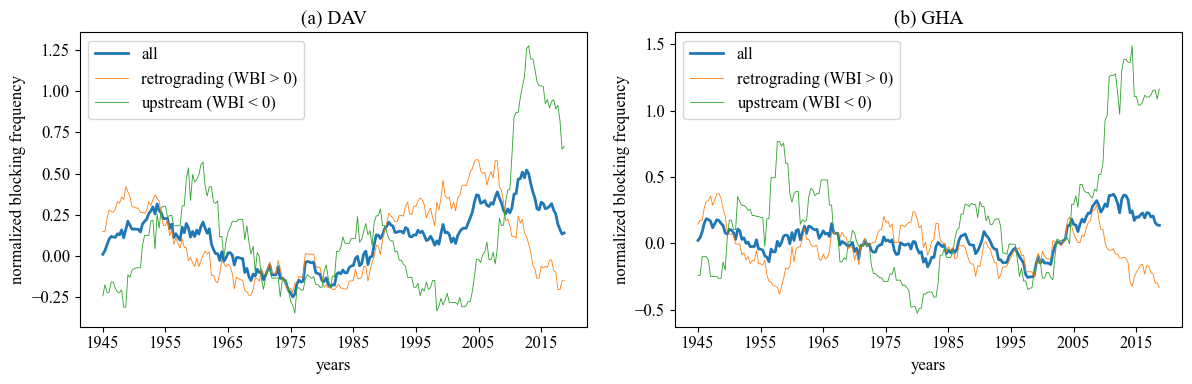

In [33]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].set_title('(a) DAV')
for i,DA in enumerate(freq_per_month_DAV_DA_normalized):
    ys,xs,locations,x_ticks = rollmean_spline_DA(DA)
    axes[0].plot(xs,ys,label=labels[i],linewidth=widths[i])
axes[0].legend()
axes[0].set_xticks(locations,x_ticks)
axes[0].set_xlabel('years')
axes[0].set_ylabel('normalized blocking frequency')

axes[1].set_title('(b) GHA')
for i,DA in enumerate(freq_per_month_GHA_DA_normalized):
    ys,xs,locations,x_ticks = rollmean_spline_DA(DA)
    axes[1].plot(xs,ys,label=labels[i],linewidth=widths[i])
axes[1].legend()
axes[1].set_xticks(locations,x_ticks)
axes[1].set_xlabel('years')
axes[1].set_ylabel('normalized blocking frequency')

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure6.png')

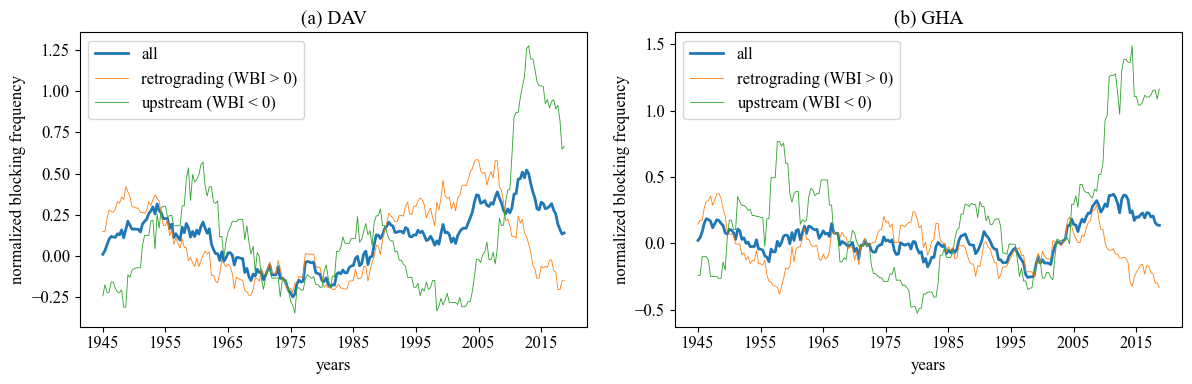

In [34]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))

axes[0].set_title('(a) DAV')
for i,DA in enumerate(freq_per_month_DAV_DA_normalized):
    ys,xs,locations,x_ticks = rollmean_spline_DA(DA,roll_avg_periods=3*10,s_spline=0)
    axes[0].plot(xs,ys,label=labels[i],linewidth=widths[i])
axes[0].legend()
axes[0].set_xticks(locations,x_ticks)
axes[0].set_xlabel('years')
axes[0].set_ylabel('normalized blocking frequency')

axes[1].set_title('(b) GHA')
for i,DA in enumerate(freq_per_month_GHA_DA_normalized):
    ys,xs,locations,x_ticks = rollmean_spline_DA(DA,roll_avg_periods=3*10,s_spline=0)
    axes[1].plot(xs,ys,label=labels[i],linewidth=widths[i])
axes[1].legend()
axes[1].set_xticks(locations,x_ticks)
axes[1].set_xlabel('years')
axes[1].set_ylabel('normalized blocking frequency')

plt.tight_layout()
plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/Figure6.png')

In [35]:
#export frequency data_arrays
block_type = ['all','retrograding','upstream']
for i,DA in enumerate(freq_per_month_DAV_DA):
    print(block_type[i],DA)
    DA.to_netcdf('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_' + block_type[i] + '_DAV_historical.nc')

#export frequency data_arrays
for i,DA in enumerate(freq_per_month_GHA_DA):
    print(block_type[i],DA)
    DA.to_netcdf('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_' + block_type[i] + '_GHA_historical.nc')

all <xarray.DataArray 'DAV monthly blocking frequency' (time: 251)> Size: 2kB
array([0.04045059, 0.09694487, 0.        , 0.11569665, 0.00580304,
       0.05034989, 0.01322751, 0.02713774, 0.02918587, 0.10723104,
       0.        , 0.05615293, 0.08253968, 0.09575013, 0.03294077,
       0.1319224 , 0.        , 0.0296979 , 0.02134039, 0.02560164,
       0.04164533, 0.10088183, 0.03055129, 0.00187745, 0.20352734,
       0.06280935, 0.08926438, 0.17848325, 0.10240655, 0.00477897,
       0.07989418, 0.15958355, 0.05854241, 0.14603175, 0.        ,
       0.04625363, 0.05167549, 0.01553166, 0.08141321, 0.02433862,
       0.08858167, 0.14490527, 0.03791887, 0.05393412, 0.03601297,
       0.12839506, 0.        , 0.        , 0.10687831, 0.05495818,
       0.06349206, 0.1617284 , 0.05854241, 0.04540024, 0.12804233,
       0.16914149, 0.01655573, 0.15449735, 0.04130398, 0.00768049,
       0.07724868, 0.05444615, 0.10718553, 0.        , 0.04198669,
       0.00870456, 0.02081129, 0.15480457, 0.020993